# Data Analytics Assignments (Sets 1-4)
This notebook is optimized for **Google Colab**.

## 📁 Step 1: Upload your CSV files
Run the cell below to upload the 4 CSV files (`hospital_data.csv`, `banking_data.csv`, `food_delivery_data.csv`, `hotel_booking_data.csv`) directly into your Colab environment.

In [6]:
!pip install pandas

In [1]:
try:
    from google.colab import files
    print('Please select the 4 CSV files to upload:')
    uploaded = files.upload()
except ImportError:
    print('Not running in Google Colab. Make sure CSVs are in the same folder.')

Not running in Google Colab. Make sure CSVs are in the same folder.


## 📦 Step 2: Import Libraries

## 🏥 Set 1: Hospital & Patient Analytics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Load and clean Hospital Data
df_hosp = pd.read_csv('hospital_data.csv')

df_hosp.dropna(subset=['Patient_ID'], inplace=True)
df_hosp.drop_duplicates(subset=['Patient_ID'], inplace=True)
df_hosp['Age'] = df_hosp['Age'].fillna(df_hosp['Age'].median())
df_hosp['Payment_Mode'] = df_hosp['Payment_Mode'].fillna('Unknown')
df_hosp['Gender'] = df_hosp['Gender'].str.title()
df_hosp['City'] = df_hosp['City'].str.title()
df_hosp['Visit_Type'] = df_hosp['Visit_Type'].str.title()
df_hosp['Admission_Status'] = df_hosp['Admission_Status'].str.title()
df_hosp = df_hosp[(df_hosp['Age'] >= 0) & (df_hosp['Age'] <= 120)]
df_hosp['Length_of_Stay_Days'] = np.where(df_hosp['Length_of_Stay_Days'] < 0, 0, df_hosp['Length_of_Stay_Days'])
df_hosp['Satisfaction_Score'] = np.clip(df_hosp['Satisfaction_Score'], 1, 10)
df_hosp['Net_Amount'] = df_hosp['Total_Bill'] - df_hosp['Insurance_Coverage']
df_hosp['Net_Amount'] = np.where(df_hosp['Net_Amount'] < 0, 0, df_hosp['Net_Amount'])

df_hosp.to_csv('Cleaned_Hospital_Data.csv', index=False)

display(df_hosp)
print("Set 1: Hospital data cleaned and exported successfully!")

,Patient_ID,Age,Payment_Mode,Gender,City,Visit_Type,Admission_Status,Length_of_Stay_Days,Satisfaction_Score,Room_Charges,Total_Bill,Insurance_Coverage,Department,Net_Amount
0,P001,86.0,Insurance,F,Surat,Follow-Up,Discharged,2,1,4174,17666,11835,General,5831
3,P004,22.0,Cash,Male,Ahmedabad,New,Admitted,0,1,2294,31854,5423,General,26431
4,P005,74.0,Cash,M,Vadodara,Followup,Discharged,5,1,2130,43952,14589,Neurology,29363
5,P006,34.0,Unknown,Female,Vadodara,New,Discharged,0,1,2095,27662,19492,Neurology,8170
6,P007,9.0,Card,Female,Ahmedabad,Follow-Up,Discharged,0,1,4772,13392,7158,Neurology,6234
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,P138,81.0,Unknown,Male,Surat,Follow-Up,Discharged,0,10,4910,42504,14599,Neurology,27905
138,P139,34.0,Unknown,F,Vadodara,New,Admitted,0,1,3568,6802,19508,Orthopedics,0
140,P141,79.0,UPI,F,Vadodara,Followup,Discharged,0,10,2152,13120,15979,Cardiology,0
141,P142,84.0,Insurance,Female,Surat,Follow-Up,Discharged,0,8,3027,44384,16388,Cardiology,27996


Set 1: Hospital data cleaned and exported successfully!


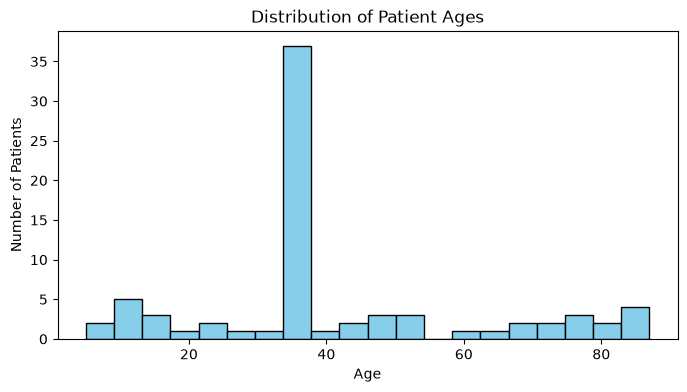

In [5]:
# Validate Data with Plot
plt.figure(figsize=(8, 4))
plt.hist(df_hosp['Age'].dropna(), bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of Patient Ages')
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.show()

## 🏦 Set 2: Banking & Loan Analytics

In [6]:
# Load and clean Banking Data
df_bank = pd.read_csv('banking_data.csv')
df_bank.drop_duplicates(subset=['Customer_ID', 'Transaction_Amount'], inplace=True)
df_bank['Customer_ID'] = df_bank['Customer_ID'].dropna()
df_bank['Annual_Income'] = df_bank['Annual_Income'].fillna(df_bank['Annual_Income'].mean())
df_bank['Credit_Score'] = df_bank['Credit_Score'].fillna(df_bank['Credit_Score'].median())
df_bank['Transaction_Amount'] = df_bank['Transaction_Amount'].fillna(0)
df_bank['Employment_Type'] = df_bank['Employment_Type'].astype(str).str.title()
df_bank['Account_Type'] = df_bank['Account_Type'].astype(str).str.upper()
df_bank['Loan_Status'] = df_bank['Loan_Status'].astype(str).str.title()
df_bank['Channel'] = df_bank['Channel'].astype(str).str.title()
df_bank = df_bank[(df_bank['Age'] >= 18) & (df_bank['Age'] <= 100)]
df_bank['Credit_Score'] = np.clip(df_bank['Credit_Score'], 300, 900)
df_bank['Interest_Rate'] = np.abs(df_bank['Interest_Rate'])
df_bank['Tenure_Years'] = np.abs(df_bank['Tenure_Years'])
df_bank['Loan_Amount'] = np.abs(df_bank['Loan_Amount'])
df_bank['Collateral_Value'] = np.abs(df_bank['Collateral_Value'])
df_bank['Transaction_Amount'] = np.abs(df_bank['Transaction_Amount'])

df_bank.to_csv('Cleaned_Banking_Data.csv', index=False)
display(df_bank)
print("Set 2: Banking data cleaned and exported successfully!")

,Customer_ID,Annual_Income,Credit_Score,Transaction_Amount,Employment_Type,Account_Type,Loan_Status,Channel,Age,Interest_Rate,Tenure_Years,Loan_Amount,Collateral_Value,Account_Balance,Loan_Type,Customer_Segment,Transaction_Type,City,Transaction_Status
3,C004,88236.1,822.0,0.0,Salaried,SAVINGS,Rejected,Online,20,2.500000,19,34000,5000,-200,Personal,Retail,Debit,Vadodara,Failed
4,C005,77619.0,624.5,2726.0,Salaried,SAVINGS,Rejected,Online,38,7.611277,16,268171,286622,26525,Personal,Retail,Debit,Vadodara,Success
10,C011,88236.1,597.0,0.0,Salaried,CURRENT,Rejected,Online,70,14.424423,18,10000,106882,21636,Personal,Retail,Credit,Delhi,Success
14,NaN,88236.1,624.5,0.0,Self,SAVINGS,Rejected,Online,33,2.500000,1,34379,157385,68861,Auto,Corporate,Credit,Mumbai,Failed
15,C016,88188.0,900.0,0.0,Self,CURRENT,Rejected,Online,47,2.500000,21,10000,136432,97590,Personal,Corporate,Credit,Delhi,Failed
16,C017,105225.0,900.0,500.0,Self,CURRENT,Rejected,Branch,69,7.375483,5,249802,5000,-200,Home,Retail,Debit,Delhi,Success
17,C018,88236.1,300.0,500.0,Salaried,SAVINGS,Rejected,Branch,25,2.500000,10,271529,5000,-200,Home,Retail,Credit,Vadodara,Failed
18,C019,88236.1,624.5,3183.0,Salaried,SAVINGS,Rejected,Branch,21,2.500000,5,288063,72221,-200,Auto,Corporate,Debit,Vadodara,Failed
19,C020,88236.1,624.5,500.0,Salaried,CURRENT,Approved,Online,26,5.038156,5,10000,5000,30661,Auto,Retail,Credit,Vadodara,Success
25,C025,88236.1,900.0,0.0,Self-Employed,CURRENT,Rejected,Branch,70,2.500000,5,10000,229556,-200,Home,Retail,Credit,Vadodara,Failed


Set 2: Banking data cleaned and exported successfully!


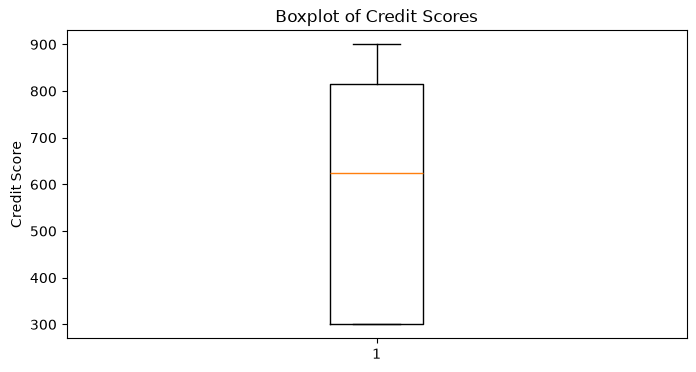

In [7]:
# Validate Data with Plot
plt.figure(figsize=(8, 4))
plt.boxplot(df_bank['Credit_Score'].dropna())
plt.title('Boxplot of Credit Scores')
plt.ylabel('Credit Score')
plt.show()

## 🍔 Set 3: Online Food Delivery Analytics

In [8]:
# Load and clean Food Delivery Data
df_food = pd.read_csv('food_delivery_data.csv')
df_food['App_Rating'] = df_food['App_Rating'].fillna(df_food['App_Rating'].mean())
df_food['Preferred_Cuisine'] = df_food['Preferred_Cuisine'].fillna('Other')
df_food['Discount'] = df_food['Discount'].fillna(0)
df_food.drop_duplicates(subset=['Order_ID'], keep='last', inplace=True)
df_food['Order_Date'] = pd.to_datetime(df_food['Order_Date'], errors='coerce')
df_food['Order_Time'] = pd.to_datetime(df_food['Order_Time'], format='%H:%M:%S', errors='coerce').dt.time
df_food['Calculated_Amount'] = df_food['Food_Amount'] + df_food['Delivery_Fee'] - df_food['Discount']
df_food['Final_Amount'] = np.where(df_food['Calculated_Amount'] > 0, df_food['Calculated_Amount'], 0)

df_food.to_csv('Cleaned_Food_Delivery_Data.csv', index=False)
display(df_food)
print("Set 3: Food delivery data cleaned and exported successfully!")

,Customer_ID,Restaurant_ID,Order_ID,App_Rating,Preferred_Cuisine,Discount,Order_Date,Order_Time,Food_Amount,Delivery_Fee,Delivery_Time_Min,Delivery_Distance_KM,Customer_Rating,Restaurant_Name,Customer_Type,Order_Status,Payment_Mode,City,Final_Amount,Calculated_Amount
0,FD_C037,R016,O001,2.995762,Indian,6.0,2023-01-10,NaT,735,81,24,13.467382,4,Restaurant_8,New,Delivered,UPI,Vadodara,810.0,810.0
1,FD_C047,R017,O002,2.995762,Italian,34.0,NaT,NaT,205,56,70,9.310294,3,Restaurant_17,Returning,Cancelled,Card,Vadodara,227.0,227.0
2,FD_C041,R005,O003,2.995762,Italian,10.0,NaT,NaT,769,31,44,10.507432,4,Restaurant_19,New,Delivered,UPI,Ahmedabad,790.0,790.0
3,FD_C034,R007,O004,3.178108,Italian,31.0,NaT,14:30:00,758,74,19,12.048397,4,Restaurant_3,Returning,Delivered,Cash,Vadodara,801.0,801.0
4,FD_C006,R011,O005,1.692342,Other,4.0,2023-01-10,NaT,756,32,47,7.978191,4,Restaurant_4,Returning,Delivered,UPI,Vadodara,784.0,784.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,FD_C013,R016,O146,2.995762,Other,0.0,NaT,NaT,198,25,53,3.146920,2,Restaurant_13,New,Delivered,Cash,Vadodara,223.0,223.0
146,FD_C006,R013,O147,2.995762,Italian,0.0,2023-01-10,14:30:00,647,88,71,9.207218,5,Restaurant_15,New,Cancelled,Cash,Vadodara,735.0,735.0
147,FD_C029,R003,O148,4.376197,Italian,0.0,NaT,NaT,195,66,31,8.082442,4,Restaurant_15,Returning,Cancelled,Cash,Vadodara,261.0,261.0
148,FD_C033,R011,O149,3.160515,Other,48.0,NaT,NaT,763,44,58,9.560359,3,Restaurant_2,Returning,Cancelled,UPI,Vadodara,759.0,759.0


Set 3: Food delivery data cleaned and exported successfully!


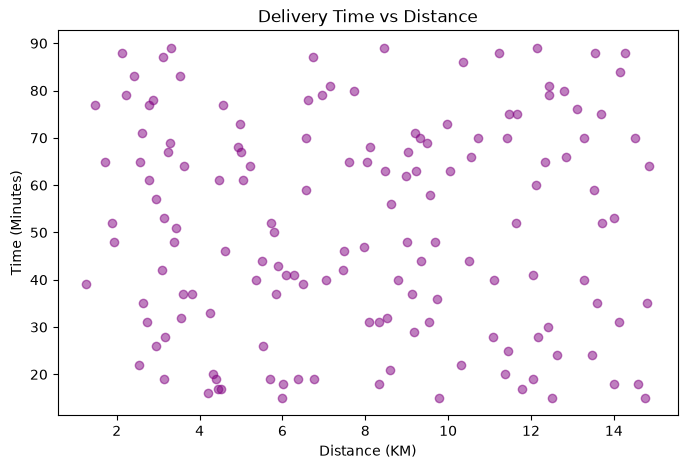

In [9]:
# Validate Data with Plot
plt.figure(figsize=(8, 5))
plt.scatter(df_food['Delivery_Distance_KM'], df_food['Delivery_Time_Min'], alpha=0.5, color='purple')
plt.title('Delivery Time vs Distance')
plt.xlabel('Distance (KM)')
plt.ylabel('Time (Minutes)')
plt.show()

## 🏨 Set 4: Hotel Booking & Occupancy Analytics

In [10]:
# Load and clean Hotel Booking Data
df_hotel = pd.read_csv('hotel_booking_data.csv')
df_hotel['Room_Type'] = df_hotel['Room_Type'].astype(str).str.strip().str.title()
df_hotel['Meal_Plan'] = df_hotel['Meal_Plan'].astype(str).str.strip().str.upper()
df_hotel['Booking_Channel'] = df_hotel['Booking_Channel'].astype(str).str.strip().str.title()
valid_status = ['Confirmed', 'Checked-In', 'Completed']
df_hotel = df_hotel[df_hotel['Booking_Status'].isin(valid_status)]
df_hotel = df_hotel[df_hotel['Guests_Count'] <= df_hotel['Room_Capacity']]
df_hotel = df_hotel[df_hotel['Occupancy_Nights'] >= 1]
expected_gross = df_hotel['Room_Rate'] * df_hotel['Occupancy_Nights']
df_hotel['Final_Amount'] = expected_gross - df_hotel['Discount']
df_hotel['Final_Amount'] = np.where(df_hotel['Final_Amount'] < 0, 0, df_hotel['Final_Amount'])

df_hotel.to_csv('Cleaned_Hotel_Data.csv', index=False)
print("Set 4: Hotel data cleaned and exported successfully!")

Set 4: Hotel data cleaned and exported successfully!


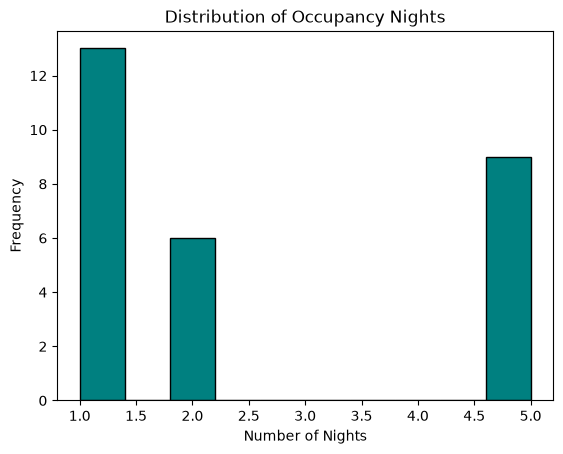

In [11]:
# Validate Data with Plot
plt.hist(df_hotel['Occupancy_Nights'].dropna(), bins=10, color='teal', edgecolor='black')
plt.title('Distribution of Occupancy Nights')
plt.xlabel('Number of Nights')
plt.ylabel('Frequency')
plt.show()